# ch03_1. 로지스틱 분류

## 두 입력값으로 클래스 0과 1 분류하기

## 개요

- Regression(리그레션, 회귀)과 Classification(클래시피케이션, 분류)의 차이를 이해합니다.
- 정확도와 분류 경계를 확인합니다.
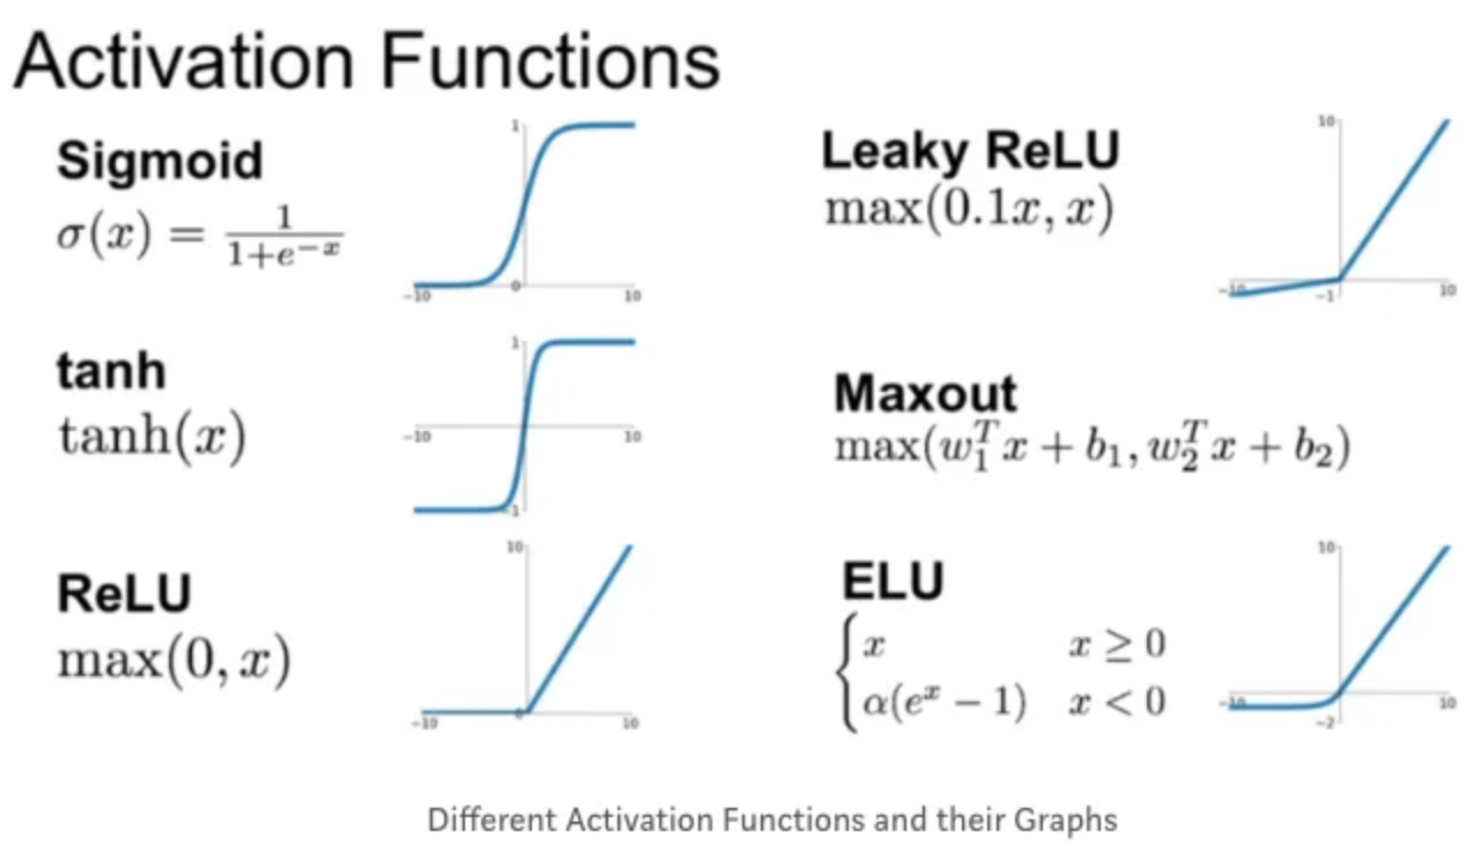


## 1. 학습 데이터 준비

입력 특성은 두 개이고, 목표값은 클래스 0 또는 1입니다.

| 데이터 | $x_1$ | $x_2$ | 클래스 |
|---:|---:|---:|---:|
| 1 | 1 | 2 | 0 |
| 2 | 2 | 3 | 0 |
| 3 | 3 | 1 | 0 |
| 4 | 4 | 3 | 1 |
| 5 | 5 | 3 | 1 |
| 6 | 6 | 2 | 1 |

- 입력 shape: `[6, 2]`
- 목표값 shape: `[6, 1]`

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

x_data = torch.tensor(
    [
        [1.0, 2.0],
        [2.0, 3.0],
        [3.0, 1.0],
        [4.0, 3.0],
        [5.0, 3.0],
        [6.0, 2.0],
    ],
    dtype=torch.float32,
)

y_data = torch.tensor(
    [[0.0], [0.0], [0.0], [1.0], [1.0], [1.0]],
    dtype=torch.float32,
)

print("입력 shape:", x_data.shape)
print("목표값 shape:", y_data.shape)
print()
print("입력 데이터:")
print(x_data)
print()
print("목표값:")
print(y_data)

입력 shape: torch.Size([6, 2])
목표값 shape: torch.Size([6, 1])

입력 데이터:
tensor([[1., 2.],
        [2., 3.],
        [3., 1.],
        [4., 3.],
        [5., 3.],
        [6., 2.]])

목표값:
tensor([[0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.]])


## 2. 로짓과 확률

선형 계층은 먼저 하나의 로짓을 계산합니다.

$$
z=w_1x_1+w_2x_2+b
$$

- **$(z)$**: Logit(로짓, 확률로 바꾸기 전 점수)

- 로짓의 범위: $(-\infty)$부터 $(+\infty)$

- 로짓은 아직 확률이 아닙니다.

로짓을 시그모이드 함수에 넣으면 0과 1 사이의 값이 됩니다.

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

$$
P(y=1|x)=\sigma(z)
$$

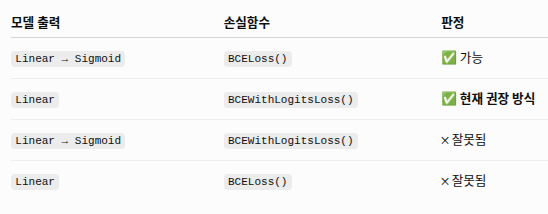
> **시그모이드 함수는 로짓을 확률로 변환합니다.**

In [ ]:
sample_logits = torch.tensor([-5.0, 0.0, 5.0])
sample_probabilities = torch.sigmoid(sample_logits)

for logit, probability in zip(
    sample_logits,
    sample_probabilities,
):
    print(
        f"로짓 {logit.item():>4.1f} "
        f"→ 확률 {probability.item():.4f}"
    )

로짓 -5.0 → 확률 0.0067
로짓  0.0 → 확률 0.5000
로짓  5.0 → 확률 0.9933


## 3. 시그모이드 그래프

- 로짓이 큰 음수이면 확률은 0에 가까워집니다.
- 로짓이 0이면 확률은 0.5입니다.
- 로짓이 큰 양수이면 확률은 1에 가까워집니다.

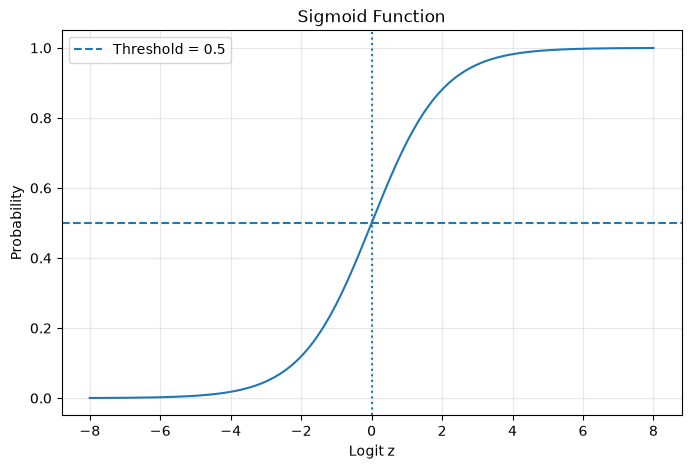

In [ ]:
logit_values = torch.linspace(-8, 8, 200)
probability_values = torch.sigmoid(logit_values)

plt.figure(figsize=(8, 5))
plt.plot(logit_values.numpy(),
    probability_values.numpy(),)
plt.axhline(0.5, linestyle="--",
    label="Threshold = 0.5",)
plt.axvline(0, linestyle=":",)
plt.xlabel("Logit z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. 확률을 클래스로 바꾸기

기본 임계값은 0.5입니다.

$$
\hat{y}=
\begin{cases}
1, & \sigma(z)\ge0.5\\
0, & \sigma(z)<0.5
\end{cases}
$$

- 확률 0.5 이상 → 클래스 1
- 확률 0.5 미만 → 클래스 0

문제의 목적에 따라 임계값은 변경할 수 있습니다.

In [ ]:
threshold = 0.5

sample_classes = (
    sample_probabilities >= threshold
).float()

for probability, predicted_class in zip(
    sample_probabilities,
    sample_classes,
):
    print(
        f"확률 {probability.item():.4f} "
        f"→ 클래스 {int(predicted_class.item())}"
    )

확률 0.0067 → 클래스 0
확률 0.5000 → 클래스 1
확률 0.9933 → 클래스 1


## 5. BCE 손실의 의미

Binary Cross Entropy(이진 교차엔트로피)는 이진분류에서 사용하는 손실함수입니다.

$$
\mathrm{BCE}
=
-\frac{1}{n}
\sum_{i=1}^{n}
\left[
y_i\log(p_i)
+
(1-y_i)\log(1-p_i)
\right]
$$

- 정답에 가까운 확률 → 손실이 작음
- 틀린 클래스를 높은 확률로 예측 → 손실이 큼

아래 예제는 실제값이 1일 때 예측 확률이 0.9인 경우와 0.1인 경우를 비교합니다.

In [ ]:
bce = nn.BCELoss()

target_one = torch.tensor([[1.0]])

good_probability = torch.tensor([[0.9]])
wrong_probability = torch.tensor([[0.1]])

good_loss = bce(
    good_probability,
    target_one,
)

wrong_loss = bce(
    wrong_probability,
    target_one,
)

print("정답 1, 예측 확률 0.9의 Loss:", good_loss.item())
print("정답 1, 예측 확률 0.1의 Loss:", wrong_loss.item())

정답 1, 예측 확률 0.9의 Loss: 0.10536054521799088
정답 1, 예측 확률 0.1의 Loss: 2.3025851249694824


## 6. 로지스틱 분류 모델

입력 특성 두 개로 로짓 하나를 계산합니다.

```python
nn.Linear(2, 1)
```

모델 안에는 시그모이드를 넣지 않습니다.

- 학습: 로짓을 `BCEWithLogitsLoss()`에 바로 입력
- 예측: 학습 후 `torch.sigmoid()`로 확률 변환

`BCEWithLogitsLoss()`는 Sigmoid와 BCE를 안정적으로 함께 계산합니다.

In [ ]:
torch.manual_seed(42)

model = nn.Linear(2, 1)

print(model)
print("가중치 shape:", model.weight.shape)
print("편향 shape:", model.bias.shape)

Linear(in_features=2, out_features=1, bias=True)
가중치 shape: torch.Size([1, 2])
편향 shape: torch.Size([1])


## 7. 모델 학습

학습 흐름은 와 같습니다.

$$
\text{순전파}
\rightarrow
\text{손실}
\rightarrow
\text{역전파}
\rightarrow
\text{갱신}
$$

MSE 대신 `BCEWithLogitsLoss()`를 사용합니다.

In [ ]:
loss_function = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
)

epochs = 2000
loss_history = []

model.train()

for epoch in range(epochs):
    # 1. 순전파: 로짓 계산
    logits = model(x_data)

    # 2. BCE 손실 계산
    loss = loss_function(
        logits,
        y_data,
    )

    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(loss.item())

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 1.1166619062423706
마지막 Loss: 0.08368653804063797


## 8. 손실 변화 확인

학습이 진행될수록 BCE Loss가 감소하는지 확인합니다.

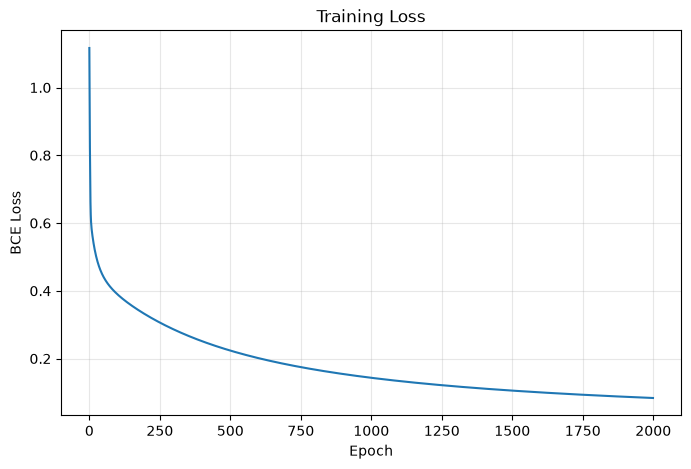

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 9. 확률·클래스·정확도 계산

학습이 끝난 뒤 다음 순서로 결과를 만듭니다.

$$
\text{Logit}
\rightarrow
\text{Sigmoid}
\rightarrow
\text{Probability}
\rightarrow
\text{Class}
$$

Accuracy(애큐러시, 정확도)는 전체 데이터 중 정답을 맞힌 비율입니다.

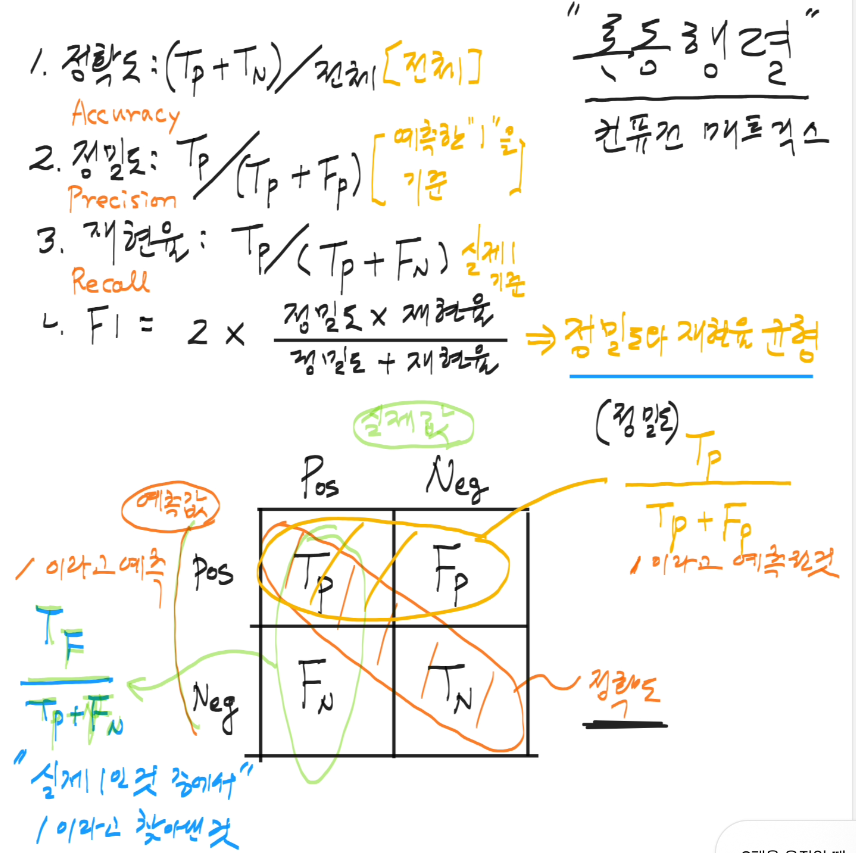

$$
\mathrm{Accuracy}
=
\frac{\text{정답 수}}
{\text{전체 데이터 수}}
$$

In [ ]:
model.eval()

with torch.no_grad():
    logits = model(x_data)
    probabilities = torch.sigmoid(logits)

    predicted_classes = (
        probabilities >= threshold
    ).float()

    accuracy = (
        predicted_classes == y_data
    ).float().mean()

print("학습된 가중치:", model.weight.detach())
print("학습된 편향:", model.bias.detach())
print(f"정확도: {accuracy.item():.4f}")

print()
print("입력             확률      예측  실제")

for x, probability, predicted, actual in zip(
    x_data,
    probabilities,
    predicted_classes,
    y_data,
):
    print(
        f"{x.tolist()}  "
        f"{probability.item():.4f}    "
        f"{int(predicted.item())}     "
        f"{int(actual.item())}"
    )

학습된 가중치: tensor([[1.9264, 0.7095]])
학습된 편향: tensor([-8.0783])
정확도: 1.0000

입력             확률      예측  실제
[1.0, 2.0]  0.0087    0     0
[2.0, 3.0]  0.1094    0     0
[3.0, 1.0]  0.1694    0     0
[4.0, 3.0]  0.8527    1     1
[5.0, 3.0]  0.9754    1     1
[6.0, 2.0]  0.9926    1     1


## 10. TP·TN·FP·FN 확인

| 구분 | 의미 |
|---|---|
| TP(티피) | 실제 1을 1로 예측 |
| TN(티엔) | 실제 0을 0으로 예측 |
| FP(에프피) | 실제 0을 1로 잘못 예측 |
| FN(에프엔) | 실제 1을 0으로 잘못 예측 |

현재 데이터는 6개뿐이므로 일반화 성능이 아니라 학습 데이터 적합도를 확인하는 예제입니다.

In [ ]:
actual_bool = y_data.bool()
predicted_bool = predicted_classes.bool()

tp = torch.sum(
    predicted_bool & actual_bool
).item()

tn = torch.sum(
    (~predicted_bool) & (~actual_bool)
).item()

fp = torch.sum(
    predicted_bool & (~actual_bool)
).item()

fn = torch.sum(
    (~predicted_bool) & actual_bool
).item()

print("TP:", tp)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)

TP: 3
TN: 3
FP: 0
FN: 0


## 11. 분류 경계 확인

확률 0.5에 해당하는 로짓은 0입니다.

$$
w_1x_1+w_2x_2+b=0
$$

이 직선이 클래스 0과 클래스 1을 나누는 Decision Boundary(디시전 바운더리, 분류 경계)입니다.

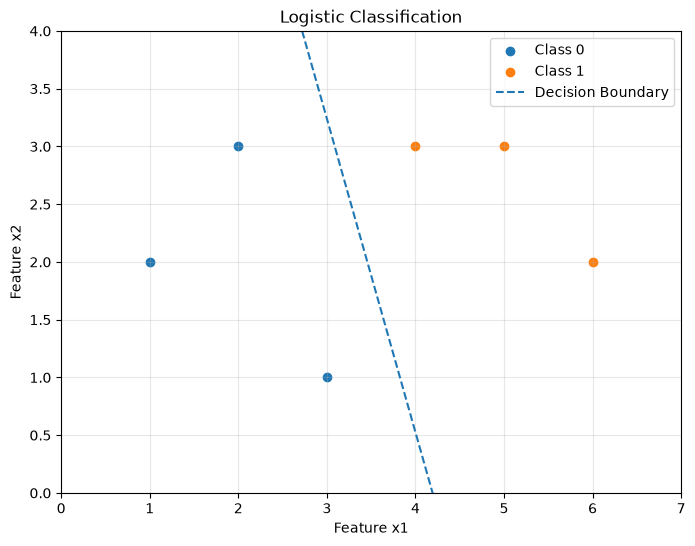

In [ ]:
weight_1 = model.weight.detach()[0, 0]
weight_2 = model.weight.detach()[0, 1]
bias = model.bias.detach()[0]

x1_line = torch.linspace(0, 7, 200)

x2_line = -(
    weight_1 * x1_line + bias
) / weight_2

class_0 = y_data[:, 0] == 0
class_1 = y_data[:, 0] == 1

plt.figure(figsize=(8, 6))

plt.scatter(
    x_data[class_0, 0].numpy(),
    x_data[class_0, 1].numpy(),
    label="Class 0",
)

plt.scatter(
    x_data[class_1, 0].numpy(),
    x_data[class_1, 1].numpy(),
    label="Class 1",
)

plt.plot(
    x1_line.numpy(),
    x2_line.numpy(),
    linestyle="--",
    label="Decision Boundary",
)

plt.xlim(0, 7)
plt.ylim(0, 4)
plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.title("Logistic Classification")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 12. 새로운 데이터 예측

학습에 사용하지 않은 입력 세 개를 모델에 넣어 로짓·확률·클래스를 확인합니다.

In [ ]:
new_x = torch.tensor(
    [
        [2.0, 1.0],
        [4.0, 2.0],
        [6.0, 4.0],
    ],
    dtype=torch.float32,
)

model.eval()

with torch.no_grad():
    new_logits = model(new_x)

    new_probabilities = torch.sigmoid(
        new_logits
    )

    new_classes = (
        new_probabilities >= threshold
    ).float()

print("입력             로짓       확률      예측")

for x, logit, probability, predicted in zip(
    new_x,
    new_logits,
    new_probabilities,
    new_classes,
):
    print(
        f"{x.tolist()}  "
        f"{logit.item():8.4f}  "
        f"{probability.item():.4f}    "
        f"{int(predicted.item())}"
    )

입력             로짓       확률      예측
[2.0, 1.0]   -3.5161  0.0289    0
[4.0, 2.0]    1.0462  0.7400    1
[6.0, 4.0]    6.3179  0.9982    1


## 14. 핵심 정리

- 로지스틱 분류는 클래스 0 또는 1을 예측합니다.
- 확률 0.5 이상이면 클래스 1, 미만이면 클래스 0으로 분류합니다.
- 현재 결과는 작은 학습 데이터의 적합도이며 일반화 성능은 아닙니다.